# Lakáspiaci árindex változása 2010 és 2025 között

Az ábra indexértékeket mutat (2025 = 100), nem abszolút lakásárakat.

CSV elérési út: /home/runner/work/Greta-Data-Science-kurzus/Greta-Data-Science-kurzus/stadat-lak0013-18.1.1.13-hu.csv


PNG mentve: /home/runner/work/Greta-Data-Science-kurzus/Greta-Data-Science-kurzus/Lakáspiaci árindex változása 2010 és 2025 között.png


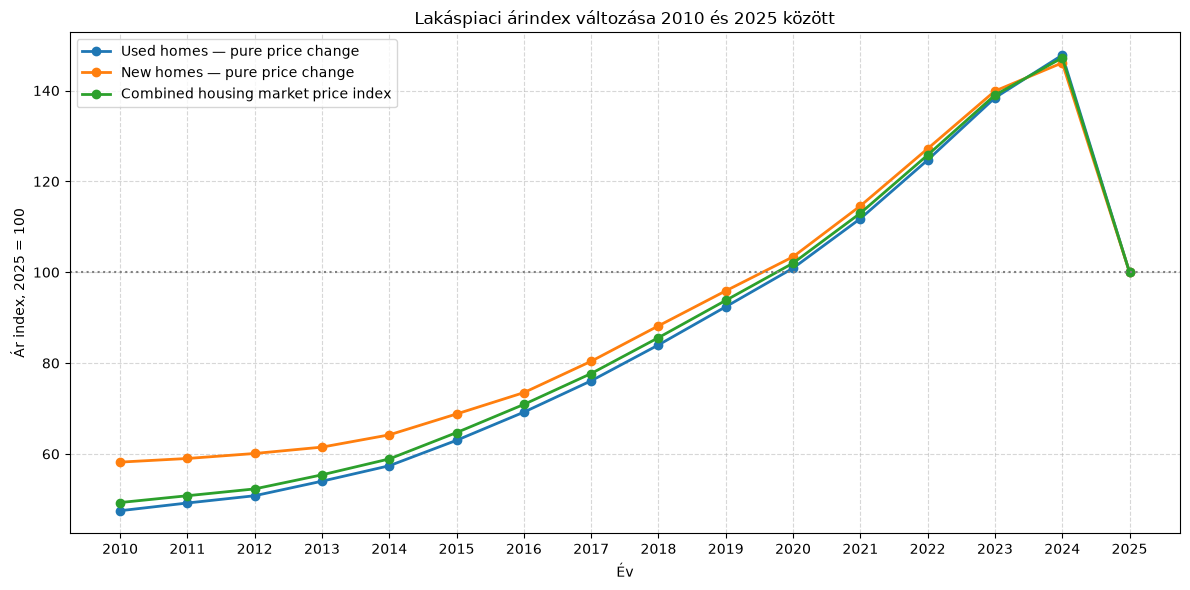

,Used homes — pure price change,New homes — pure price change,Combined housing market price index
2010,47.5,58.2,49.3
2011,49.2,59.0,50.8
2012,50.8,60.1,52.3
2013,54.0,61.5,55.4
2014,57.4,64.2,58.9
2015,63.0,68.8,64.7
2016,69.2,73.5,70.9
2017,76.1,80.4,77.7
2018,84.0,88.2,85.6
2019,92.4,95.9,93.8


In [1]:
from pathlib import Path
import io
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt

TITLE = "Lakáspiaci árindex változása 2010 és 2025 között"
TARGET_CSV_NAME = "stadat-lak0013-18.1.1.13-hu.csv"
TARGET_SECTION = "2025 = 100,0%"
TARGET_YEAR_RANGE = [str(y) for y in range(2010, 2026)]


def normalize_text(value: str) -> str:
    value = "" if value is None else str(value)
    value = unicodedata.normalize("NFKC", value)
    return " ".join(value.lower().split())


def locate_csv(start: Path, filename: str) -> Path:
    candidates = list(start.rglob(filename))
    if not candidates:
        raise FileNotFoundError(f"A fájl nem található a repóban: {filename}")
    return sorted(candidates, key=lambda p: len(p.parts))[0]


def read_hungarian_csv(path: Path) -> pd.DataFrame:
    raw = path.read_bytes()
    last_error = None
    for enc in ("utf-8-sig", "utf-8", "cp1250", "iso-8859-2"):
        try:
            txt = raw.decode(enc)
            return pd.read_csv(io.StringIO(txt), sep=";", dtype=str, engine="python")
        except UnicodeDecodeError as exc:
            last_error = exc
    raise UnicodeDecodeError("csv", b"", 0, 1, f"Nem sikerült dekódolni a CSV-t: {last_error}")


repo_root = Path.cwd()
csv_path = locate_csv(repo_root, TARGET_CSV_NAME)
print(f"CSV elérési út: {csv_path}")

df = read_hungarian_csv(csv_path)
df.columns = [str(c).strip() for c in df.columns]

year_columns = [c for c in df.columns if c in TARGET_YEAR_RANGE]
if set(TARGET_YEAR_RANGE) - set(year_columns):
    missing = sorted(set(TARGET_YEAR_RANGE) - set(year_columns))
    raise ValueError(f"Hiányzó év oszlop(ok): {missing}")

non_year_columns = [c for c in df.columns if c not in year_columns]

section_series = (
    df[non_year_columns]
    .fillna("")
    .agg(" ".join, axis=1)
    .map(normalize_text)
)

is_section_header = section_series.str.contains("= 100,0%")
section_context = section_series.where(is_section_header).ffill().fillna("")
df = df.assign(_section=section_context)

section_norm = normalize_text(TARGET_SECTION)
df = df[df["_section"].str.contains(section_norm, na=False)].copy()

row_text = (
    df[non_year_columns]
    .fillna("")
    .agg(" ".join, axis=1)
    .map(normalize_text)
)

series_specs = [
    ("használt lakások", "tiszta árváltozás", "Used homes — pure price change"),
    ("új lakások", "tiszta árváltozás", "New homes — pure price change"),
    ("összevont lakáspiaci árindex", "", "Combined housing market price index"),
]

plot_df = pd.DataFrame(index=TARGET_YEAR_RANGE)
for category, indicator, label in series_specs:
    mask = row_text.str.contains(normalize_text(category), na=False)
    if indicator:
        mask &= row_text.str.contains(normalize_text(indicator), na=False)
    matched = df[mask]
    if matched.empty:
        raise ValueError(f"Nem található sor ehhez: {label}")
    values = (
        matched.iloc[0][TARGET_YEAR_RANGE]
        .astype(str)
        .str.replace(" ", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(",", ".", regex=False)
    )
    plot_df[label] = pd.to_numeric(values, errors="coerce")

if plot_df.isna().any().any():
    raise ValueError("Legalább egy kiválasztott idősorban nem numerikus/hiányzó érték van.")

fig, ax = plt.subplots(figsize=(12, 6))
for col in plot_df.columns:
    ax.plot(plot_df.index.astype(int), plot_df[col], marker="o", linewidth=2, label=col)

ax.set_title(TITLE)
ax.set_xlabel("Év")
ax.set_ylabel("Ár index, 2025 = 100")
ax.set_xticks([int(y) for y in TARGET_YEAR_RANGE])
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(100, color="gray", linestyle=":", linewidth=1.5)
ax.legend()
fig.tight_layout()

png_path = Path(TITLE + ".png")
fig.savefig(png_path, dpi=150, bbox_inches="tight")
print(f"PNG mentve: {png_path.resolve()}")

plt.show()
plot_df


A görbék 2010–2025 közötti indexértékeket mutatnak, ahol a 2025-ös szint 100-nak felel meg.